# 🎓 Student Performance Prediction — Phase 6: Improvements
Feature Importance · Hyperparameter Tuning · At-Risk Detection (binary)

## 0️⃣ Setup (self-contained)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/student_data.csv')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Features WITHOUT past grades (early-warning design)
X = df.drop(columns=['G1', 'G2', 'G3'])
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Feature matrix:", X.shape)


Feature matrix: (395, 39)


## 1️⃣ Feature Importance — Random Forest
*Which early-knowable factors matter most?* Gold for your report's discussion section.

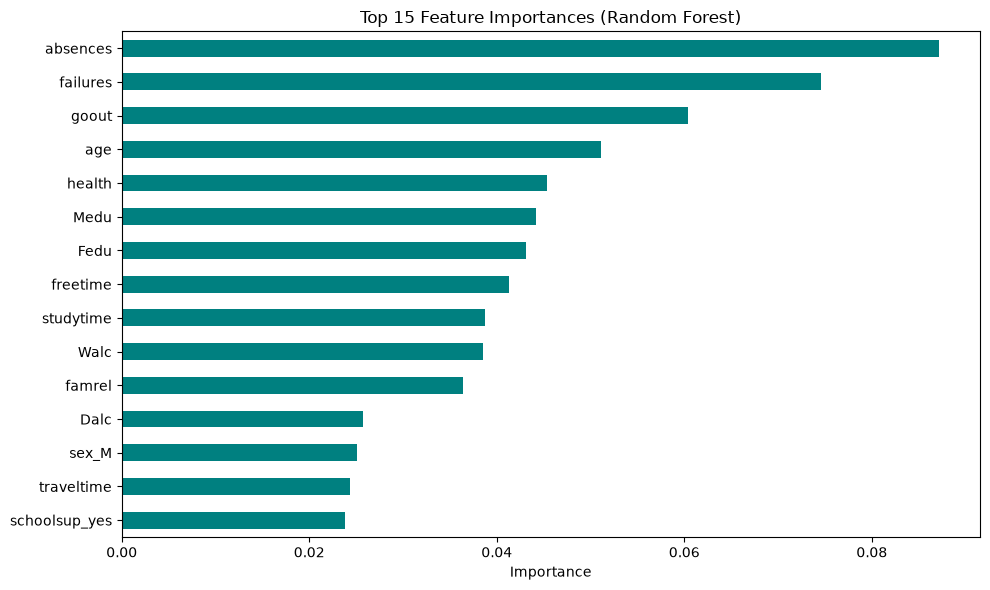

In [2]:
# Binary at-risk target needed here too (defined properly in section 2, quick version for importance)
y_bin_importance = (df['G3'] < 10).astype(int)

rf_imp = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf_imp.fit(X, y_bin_importance)

importances = pd.Series(rf_imp.feature_importances_, index=X.columns)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top15.sort_values().plot(kind='barh', color='teal')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


## 2️⃣ ⭐ The At-Risk Model (binary) — YOUR PROJECT'S CORE
**At-Risk = final grade F (G3 < 10).** For a warning system, *recall on the At-Risk class* is the metric that matters: missing an at-risk student is the worst outcome.

In [3]:
# Binary target: 1 = At-Risk (fail), 0 = Safe
y_bin = (df['G3'] < 10).astype(int)
print("Class balance:")
print(y_bin.map({1: 'At-Risk', 0: 'Safe'}).value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y_bin, test_size=0.2, random_state=42, stratify=y_bin
)

print("Train:", X_train.shape, "| Test:", X_test.shape)


Class balance:
G3
Safe       265
At-Risk    130
Name: count, dtype: int64
Train: (316, 39) | Test: (79, 39)


## 3️⃣ Train Logistic Regression vs Random Forest (binary)

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

bin_models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

bin_results = {}
for name, model in bin_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    bin_results[name] = acc
    print("=" * 60)
    print("BINARY MODEL:", name, " | Accuracy:", round(acc, 3))
    print("=" * 60)
    # target_names: label 0=Safe, 1=At-Risk -> recall of At-Risk is the KEY number
    print(classification_report(y_test, y_pred, target_names=['Safe', 'At-Risk']))


BINARY MODEL: Logistic Regression  | Accuracy: 0.709
              precision    recall  f1-score   support

        Safe       0.81      0.74      0.77        53
     At-Risk       0.55      0.65      0.60        26

    accuracy                           0.71        79
   macro avg       0.68      0.69      0.68        79
weighted avg       0.73      0.71      0.71        79

BINARY MODEL: Random Forest  | Accuracy: 0.722
              precision    recall  f1-score   support

        Safe       0.76      0.85      0.80        53
     At-Risk       0.60      0.46      0.52        26

    accuracy                           0.72        79
   macro avg       0.68      0.66      0.66        79
weighted avg       0.71      0.72      0.71        79



## 4️⃣ Hyperparameter Tuning — GridSearchCV on Random Forest
Searches a small grid and picks the best combo by 5-fold cross-validation. Takes ~1-2 minutes.

In [5]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid, cv=5, scoring='recall', n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV recall:", round(grid.best_score_, 3))

best_rf = grid.best_estimator_
y_pred_best = best_rf.predict(X_test)
print("Tuned RF test accuracy:", round(accuracy_score(y_test, y_pred_best), 3))
print(classification_report(y_test, y_pred_best, target_names=['Safe', 'At-Risk']))


Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best CV recall: 0.44
Tuned RF test accuracy: 0.709
              precision    recall  f1-score   support

        Safe       0.77      0.81      0.79        53
     At-Risk       0.57      0.50      0.53        26

    accuracy                           0.71        79
   macro avg       0.67      0.66      0.66        79
weighted avg       0.70      0.71      0.70        79



## 5️⃣ Confusion Matrix of the tuned model
Reading it: **bottom-left = at-risk students the system MISSED** (worst case). **bottom-right = caught in time** (the system's value).

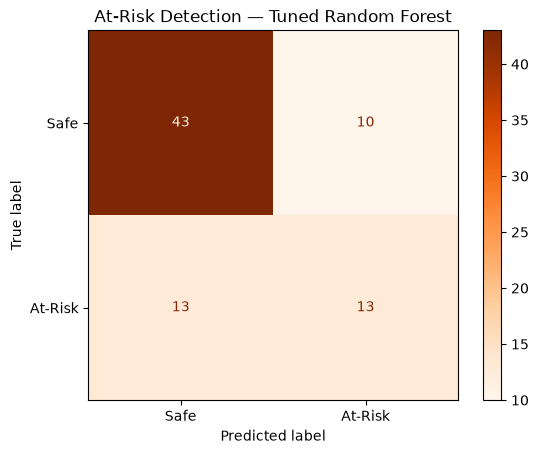

At-Risk students caught in time (recall): 13 / 26 = 0.5
False alarms (Safe flagged as at-risk): 10 / 53 = 0.19


In [6]:
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(cm, display_labels=['Safe', 'At-Risk'])
disp.plot(cmap='Oranges')
plt.title('At-Risk Detection — Tuned Random Forest')
plt.show()

tn, fp, fn, tp = cm.ravel()
print("At-Risk students caught in time (recall):", tp, "/", tp + fn, "=", round(tp / (tp + fn), 2))
print("False alarms (Safe flagged as at-risk):", fp, "/", tn + fp, "=", round(fp / (tn + fp), 2))


In [1]:
%pip install streamlit

  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/10.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/10.3 MB 5.9 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/10.3 MB 5.0 MB/s eta 0:00:02
   ------------ --------------------------- 3.1/10.3 MB 5.4 MB/s eta 0:00:02
   --------------- ------------------------ 3.9/10.3 MB 5.2 MB/s eta 0:00:02
   -------------------- ------------------- 5.2/10.3 MB 5.5 MB/s eta 0:00:01
   ------------------------- -------------- 6.6/10.3 MB 5.6 MB/s eta 0:00:01
   ------------------------------ --------- 7.9/10.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------- ----- 8.9/10.3 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------  10.2/10.3 MB 5.6 MB/s eta 0:00:01
   ----------------------------------


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
